# 4 · Plotting

`MeteoRaster` carries a handful of ready-made plots. They are deliberately plain — enough
to look at a dataset while you work on it. For anything publication-shaped, go through
`to_xarray()` (notebook 2) and plot it yourself.

**Needs:** `matplotlib` and `cartopy` (conda). `cartopy`, `matplotlib` and `seaborn` are
imported *on demand*, so `import meteoraster` still works in a container that has none of
them — a missing one raises at the call site, with the command to install it.

> One habit worth knowing: these methods call `plt.show()` themselves, which in a notebook
> **displays and closes** the figure. Styling applied after the call is lost. For the
> scatter plots, set it up on an axes you pass in; for the maps, `xarray`'s own plotting
> owns the title. `plot_seasonal` is the exception — it just returns its axes.

In [1]:
import importlib.util
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Environment noise, nothing to do with meteoraster: xarray probes every NetCDF/GRIB
# backend it can find (cfgrib needs the ecCodes binary), and this conda env's h5py and
# HDF5 builds differ by a patch release.
warnings.filterwarnings('ignore', message='(?s).*ecCodes.*')
warnings.filterwarnings('ignore', message='(?s).*h5py is running against HDF5.*')

# Report warnings without their absolute path, so the committed output does not carry
# one machine's directory layout. The warnings themselves stay visible.
def brief_warning(message, category, filename, lineno, line=None):
    return '%s:%d: %s: %s\n' % (Path(filename).name, lineno, category.__name__, message)


warnings.formatwarning = brief_warning

# Run straight from a clone: if `meteoraster` is not installed in this environment,
# fall back to the repository root one level up.
if importlib.util.find_spec('meteoraster') is None:
    sys.path.insert(0, str(Path('..').resolve()))

from meteoraster import MeteoRaster

RESOURCES = Path('..') / 'tests' / 'resources'

plt.rcParams['figure.dpi'] = 100

temperature = MeteoRaster.load(RESOURCES / 'tethys_NOAA_GFS_0.25_2026.05.18.nct', verbose=False)
rain = MeteoRaster.load(RESOURCES / 'tethys_NOAA_GFS_0.25_2026.02.02.nct', verbose=False)

print('temperature: %s in %s' % (temperature.data.shape, temperature.units))
print('rain       : %s in %s' % (rain.data.shape, rain.units))

temperature: (7, 1, 129, 29, 57) in C
rain       : (7, 1, 129, 29, 57) in mm/3h


## A map of the mean

`create_plot` builds a `cartopy` axes; `plot_mean` averages over production, member and
leadtime and draws it there. `coastline` and `borders` come from Natural Earth.
`plot_mean` returns `(ax, cbar)`.

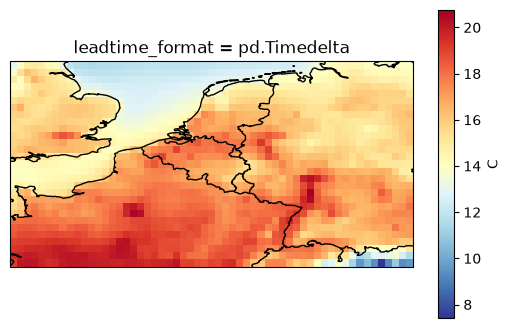

In [2]:
ax = temperature.create_plot(central_longitude=5, figsize=(6.5, 4))
ax, cbar = temperature.plot_mean(ax=ax, coastline=True, borders=True,
                                 colorbar=True, cmap='RdYlBu_r')

Called without an `ax`, `plot_mean` makes its own — but then it needs
`central_longitude`, because that is what it hands to `create_plot`:

```python
ax, cbar = mr.plot_mean(central_longitude=5, coastline=True)
```

`create_plot` also takes `extent=[west, east, south, north]`, a `figsize`, and a
`projection_fun` (any `cartopy.crs` class) when `PlateCarree` is not what you want.

That `leadtime_format = pd.Timedelta` heading is xarray's, not ours: it titles a map with
whatever scalar coordinates the array carries. Which brings up the `xarray=` argument —
`plot_mean` averages over production, member and leadtime by default, but hand it a
`DataArray` and it draws that instead. Any reduction you like, and a chance to drop the
scalar coordinate on the way:

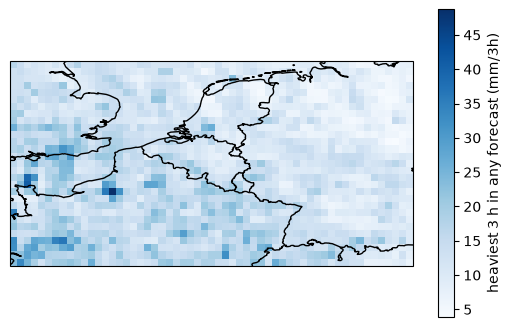

In [3]:
field = (rain.to_xarray()
         .max(dim=['production_datetime', 'ensemble_member', 'leadtime'])
         .drop_vars('leadtime_format'))          # the coordinate xarray would title with

ax = rain.create_plot(central_longitude=5, figsize=(6.5, 4))
ax, cbar = rain.plot_mean(ax=ax, xarray=field, coastline=True, borders=True, cmap='Blues',
                          colorbar_label='heaviest 3 h in any forecast (%s)' % rain.units)

## The grid itself, unprojected

`plot_mean_projected` scatters the same mean at the **true** stored coordinates, and
`plot_coordinates` draws just the grid points. Both are diagnostics: they show where the
cells actually are, which matters on a curvilinear grid whose rows are not constant
latitude.

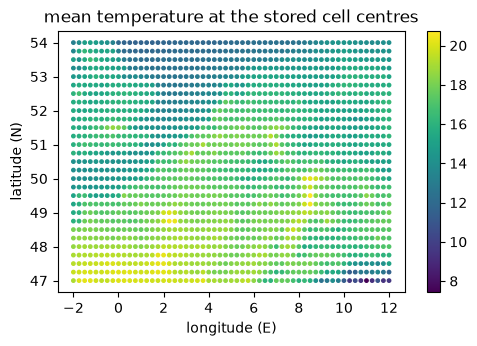

In [4]:
fig, ax = plt.subplots(figsize=(5.6, 3.4))
ax.set(xlabel='longitude (E)', ylabel='latitude (N)',
       title='mean temperature at the stored cell centres')
temperature.plot_mean_projected(ax=ax, s=6)

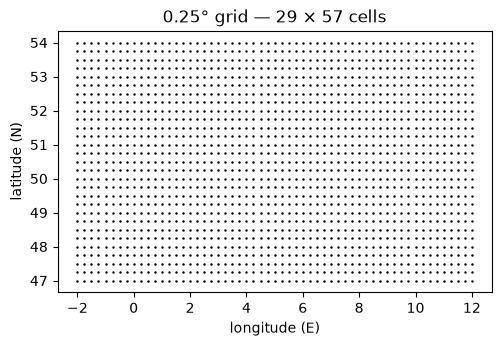

In [5]:
fig, ax = plt.subplots(figsize=(5.6, 3.4))
ax.set(xlabel='longitude (E)', ylabel='latitude (N)',
       title='0.25° grid — %d × %d cells' % rain.data.shape[-2:])
rain.plot_coordinates(ax=ax, markersize=1.5)

## What is actually there

`plot_availability` puts production date against event date and shows how many members
carry data. It is the picture of an archive's holes — and the February file has one, a
production that is entirely missing.

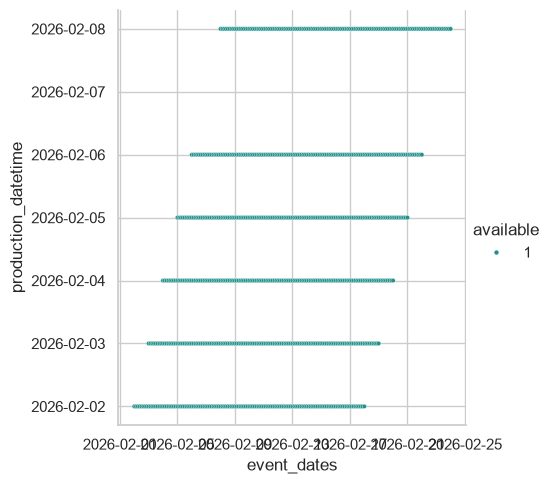

In [6]:
rain.plot_availability()

Each diagonal is one forecast issue reaching forward in time. Read a vertical slice and
you get every forecast that ever covered that event date — the overlap notebook 5 plots.

## Seasonal behaviour

`plot_seasonal` extracts the nearest pixel, takes a centred rolling mean and draws it
against day of year with a 95 % percentile interval.

It is built for **long reanalysis series**, where a day-of-year climatology means
something. Seven production dates only demonstrate the call — hence `window=3` rather than
the default 31.

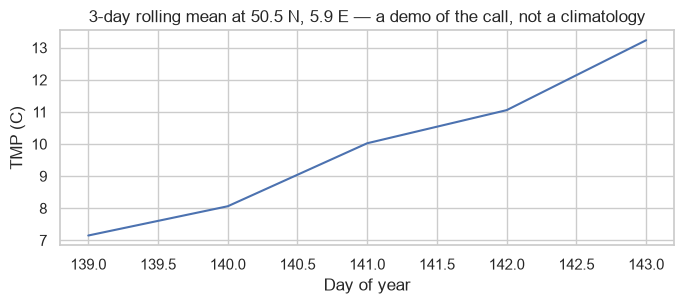

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax = temperature.plot_seasonal(lat=50.5, lon=5.9, window=3, ax=ax)
ax.set_ylabel('%s (%s)' % (temperature.variable, temperature.units))
ax.set_title('3-day rolling mean at 50.5 N, 5.9 E — a demo of the call, not a climatology')
fig.tight_layout()

## Overlaying vector data

Two helpers add shapefile geometry to a `cartopy` axes:

```python
ax, cbar = mr.plot_mean(central_longitude=5, coastline=True)
mr.add_shapefile(ax, 'basin.shp', edgecolor='crimson', facecolor='none')
mr.add_shape(ax, 'basin.shp', color='crimson', linewidth=1.5)
```

`add_shapefile` adds every geometry in one call; `add_shape` walks the records and outlines
them individually. There is no shapefile among the test fixtures, so these are not executed
here — but notebook 6 draws the catchment **centroids** from `catchments.kml` on a map,
which needs no shapefile.

---
**Next:** [05 · Point time series](05_point_time_series.ipynb).